In [1]:


import os
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

print("TensorFlow Version :", tf.__version__)

TensorFlow Version : 2.21.0


In [3]:
X_train = np.load("deep_learning_dataset/X_train.npy")
X_test  = np.load("deep_learning_dataset/X_test.npy")

y_train = np.load("deep_learning_dataset/y_train.npy")
y_test  = np.load("deep_learning_dataset/y_test.npy")

In [5]:
# ------------------------------------------------------------
# Loading the  Training Dataset
# ------------------------------------------------------------



print("Training Shape :", X_train.shape)
print("Testing Shape  :", X_test.shape)

Training Shape : (380835, 1024, 3)
Testing Shape  : (95209, 1024, 3)


In [6]:
print(y_train.shape)
print(y_test.shape)

(380835, 10)
(95209, 10)


In [7]:
print(y_train[0])

[0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]


In [8]:
print(y_train[1])

[0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]


In [9]:
print(np.unique(y_train))
print(np.unique(y_test))

[0. 1.]
[0. 1.]


In [10]:
import numpy as np

y_train = np.load("deep_learning_dataset/y_train.npy")
y_test = np.load("deep_learning_dataset/y_test.npy")

# Convert one-hot → integer labels
y_train = np.argmax(y_train, axis=1)
y_test = np.argmax(y_test, axis=1)

# Save back
np.save("deep_learning_dataset/y_train.npy", y_train)
np.save("deep_learning_dataset/y_test.npy", y_test)

In [11]:
print(y_train[0])

4


In [12]:
print(np.unique(y_train))
print(np.unique(y_test))

[0 1 2 3 4 5 6 7 8 9]
[0 1 2 3 4 5 6 7 8 9]


In [13]:
BATCH_SIZE = 64

AUTOTUNE = tf.data.AUTOTUNE

train_dataset = tf.data.Dataset.from_tensor_slices(
    (X_train, y_train)
)

train_dataset = (
    train_dataset
    .shuffle(5000)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

test_dataset = tf.data.Dataset.from_tensor_slices(
    (X_test, y_test)
)

test_dataset = (
    test_dataset
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

In [14]:
for x,y in train_dataset.take(1):

    print(x.shape)

    print(y.shape)

(64, 1024, 3)
(64,)


In [15]:
NUM_CLASSES = 10

INPUT_SHAPE = (1024,3)

DROPOUT = 0.5

In [16]:
print("="*50)

print("Training Samples :", len(X_train))

print("Testing Samples  :", len(X_test))

print("Input Shape      :", INPUT_SHAPE)

print("Number Classes   :", NUM_CLASSES)

print("="*50)

Training Samples : 380835
Testing Samples  : 95209
Input Shape      : (1024, 3)
Number Classes   : 10


In [17]:
print("Training Mean :", X_train.mean())
print("Training Std  :", X_train.std())

print("Testing Mean  :", X_test.mean())
print("Testing Std   :", X_test.std())

Training Mean : 4.89976e-08
Training Std  : 1.000006
Testing Mean  : 1.6278567e-05
Testing Std   : 0.99811006


In [43]:
# ============================================================
# Multi-Scale Feature Extraction Block
# ============================================================

class MultiScaleFeatureExtractionBlock(tf.keras.layers.Layer):

    def __init__(self, filters=64, **kwargs):

        super().__init__(**kwargs)

        self.filters = filters
        # -------- Branch 1 (Kernel = 3) --------
        self.conv3 = layers.Conv1D(
            filters=filters,
            kernel_size=3,
            padding="same",
            use_bias=False
        )

        self.bn3 = layers.BatchNormalization()

        # -------- Branch 2 (Kernel = 5) --------
        self.conv5 = layers.Conv1D(
            filters=filters,
            kernel_size=5,
            padding="same",
            use_bias=False
        )

        self.bn5 = layers.BatchNormalization()

        # -------- Branch 3 (Kernel = 9) --------
        self.conv9 = layers.Conv1D(
            filters=filters,
            kernel_size=9,
            padding="same",
            use_bias=False
        )

        self.bn9 = layers.BatchNormalization()

        self.relu = layers.ReLU()

    def call(self, inputs, training=False):

        # ---------- Branch 1 ----------
        f3 = self.conv3(inputs)
        f3 = self.bn3(f3, training=training)
        f3 = self.relu(f3)

        # ---------- Branch 2 ----------
        f5 = self.conv5(inputs)
        f5 = self.bn5(f5, training=training)
        f5 = self.relu(f5)

        # ---------- Branch 3 ----------
        f9 = self.conv9(inputs)
        f9 = self.bn9(f9, training=training)
        f9 = self.relu(f9)

        return f3, f5, f9

In [21]:
block = MultiScaleFeatureExtractionBlock(filters=64)

dummy = tf.random.normal((2,1024,32))

f3, f5, f9 = block(dummy)

print("Kernel-3 :", f3.shape)
print("Kernel-5 :", f5.shape)
print("Kernel-9 :", f9.shape)

Kernel-3 : (2, 1024, 64)
Kernel-5 : (2, 1024, 64)
Kernel-9 : (2, 1024, 64)


In [44]:
# ============================================================
# Adaptive Gated Feature Fusion
# ============================================================

class AdaptiveGatedFeatureFusion(tf.keras.layers.Layer):

    def __init__(self, **kwargs):

        super().__init__(**kwargs)

        self.gap = layers.GlobalAveragePooling1D()

        # Shared scoring layer
        self.score = layers.Dense(1)

        self.softmax = layers.Softmax(axis=1)

    def call(self, f3, f5, f9):

        # -------- Global descriptors --------
        s3 = self.gap(f3)
        s5 = self.gap(f5)
        s9 = self.gap(f9)

        # -------- Branch scores --------
        score3 = self.score(s3)
        score5 = self.score(s5)
        score9 = self.score(s9)

        # -------- Stack scores --------
        scores = tf.concat(
            [score3, score5, score9],
            axis=1
        )

        weights = self.softmax(scores)

        # -------- Split weights --------
        w3 = weights[:, 0]
        w5 = weights[:, 1]
        w9 = weights[:, 2]

        # -------- Reshape --------
        w3 = tf.reshape(w3, (-1, 1, 1))
        w5 = tf.reshape(w5, (-1, 1, 1))
        w9 = tf.reshape(w9, (-1, 1, 1))

        # -------- Weighted Fusion --------
        output = (
            w3 * f3 +
            w5 * f5 +
            w9 * f9
        )

        return output

In [27]:
block = MultiScaleFeatureExtractionBlock(filters=64)

fusion = AdaptiveGatedFeatureFusion()

dummy = tf.random.normal((2,1024,32))

f3, f5, f9 = block(dummy)

output = fusion(f3, f5, f9)

print(output.shape)

(2, 1024, 64)


In [45]:

# Residual Temporal Block

class ResidualTemporalBlock(tf.keras.layers.Layer):

    def __init__(self, filters=64, **kwargs):

        super().__init__(**kwargs)

        self.filters = filters
        self.conv1 = layers.Conv1D(
            filters,
            kernel_size=3,
            padding="same",
            use_bias=False
        )

        self.bn1 = layers.BatchNormalization()

        self.conv2 = layers.Conv1D(
            filters,
            kernel_size=3,
            padding="same",
            use_bias=False
        )

        self.bn2 = layers.BatchNormalization()

        self.relu = layers.ReLU()

        self.add = layers.Add()

    def call(self, inputs, training=False):

        shortcut = inputs

        x = self.conv1(inputs)
        x = self.bn1(x, training=training)
        x = self.relu(x)

        x = self.conv2(x)
        x = self.bn2(x, training=training)

        x = self.add([x, shortcut])

        x = self.relu(x)

        return x

In [29]:
residual = ResidualTemporalBlock(filters=64)

dummy = tf.random.normal((2,1024,64))

output = residual(dummy)

print(output.shape)

(2, 1024, 64)


In [46]:
# ============================================================
# True Cross-Channel Attention
# ============================================================

class CrossChannelAttention(tf.keras.layers.Layer):

    def __init__(self, channels=64, **kwargs):

        super().__init__(**kwargs)

        self.channels = channels
        self.gap = layers.GlobalAveragePooling1D()

        self.query = layers.Dense(channels)

        self.key = layers.Dense(channels)

        self.value = layers.Dense(channels)

        self.softmax = layers.Softmax(axis=-1)

        self.out = layers.Dense(channels)

    def call(self, inputs):

        shortcut = inputs

        # ---------------------------------
        # Global Channel Descriptor
        # ---------------------------------

        x = self.gap(inputs)

        # (Batch,64)

        Q = self.query(x)

        K = self.key(x)

        V = self.value(x)

        # ---------------------------------
        # Attention Matrix
        # ---------------------------------

        Q = tf.expand_dims(Q, axis=2)

        K = tf.expand_dims(K, axis=1)

        attention = tf.matmul(Q, K)

        attention = self.softmax(attention)

        # ---------------------------------
        # Value
        # ---------------------------------

        V = tf.expand_dims(V, axis=2)

        out = tf.matmul(attention, V)

        out = tf.squeeze(out, axis=-1)

        out = self.out(out)

        out = tf.expand_dims(out, axis=1)

        # ---------------------------------
        # Reweight Features
        # ---------------------------------

        output = inputs * out

        output = output + shortcut

        return output

In [33]:
attention = CrossChannelAttention(channels=64)

dummy = tf.random.normal((2,1024,64))

output = attention(dummy)

print(output.shape)

(2, 1024, 64)


In [34]:
# ============================================================
# Initial Convolution Block
# ============================================================

def InitialConv(inputs):

    x = layers.Conv1D(
        filters=32,
        kernel_size=3,
        padding="same",
        use_bias=False
    )(inputs)

    x = layers.BatchNormalization()(x)

    x = layers.ReLU()(x)

    return x

In [35]:
# ============================================================
# MHSF-CA Net
# ============================================================

def build_mhsf_ca_net(input_shape=(1024,3),
                      num_classes=10):

    inputs = layers.Input(shape=input_shape)

    # --------------------------------------------------
    # Initial Convolution
    # --------------------------------------------------

    x = InitialConv(inputs)

    # --------------------------------------------------
    # Multi-Scale Feature Extraction
    # --------------------------------------------------

    multiscale = MultiScaleFeatureExtractionBlock(filters=64)

    f3, f5, f9 = multiscale(x)

    # --------------------------------------------------
    # Adaptive Gated Feature Fusion
    # --------------------------------------------------

    fusion = AdaptiveGatedFeatureFusion()

    x = fusion(f3, f5, f9)

    # --------------------------------------------------
    # Residual Temporal Block
    # --------------------------------------------------

    residual = ResidualTemporalBlock(filters=64)

    x = residual(x)

    # --------------------------------------------------
    # Cross Channel Attention
    # --------------------------------------------------

    attention = CrossChannelAttention(channels=64)

    x = attention(x)

    # --------------------------------------------------
    # Global Average Pooling
    # --------------------------------------------------

    x = layers.GlobalAveragePooling1D()(x)

    # --------------------------------------------------
    # Classification Head
    # --------------------------------------------------

    x = layers.Dense(
        128,
        activation="relu"
    )(x)

    x = layers.Dropout(0.5)(x)

    outputs = layers.Dense(
        num_classes,
        activation="softmax"
    )(x)

    model = Model(inputs, outputs)

    return model

In [36]:
model = build_mhsf_ca_net()

In [37]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)      │ (None, 1024, 3)           │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ conv1d_14 (Conv1D)            │ (None, 1024, 32)          │             288 │ input_layer[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ batch_normalization_14        │ (None, 1024, 32)          │             128 │ conv1d_14[0][0]            │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ re_lu_5 (ReLU)                │ (None, 1024, 32)          │               0 │ batch_normalization_14[0]… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ multi_scale_feature_extracti… │ [(None, 1024, 64), (None, │          35,584 │ re_lu_5[0][0]              │
│ (MultiScaleFeatureExtraction… │ 1024, 64), (None, 1024,   │                 │                            │
│                               │ 64)]                      │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ adaptive_gated_feature_fusio… │ (None, 1024, 64)          │              65 │ multi_scale_feature_extra… │
│ (AdaptiveGatedFeatureFusion)  │                           │                 │ multi_scale_feature_extra… │
│                               │                           │                 │ multi_scale_feature_extra… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ residual_temporal_block_1     │ (None, 1024, 64)          │          25,088 │ adaptive_gated_feature_fu… │
│ (ResidualTemporalBlock)       │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ cross_channel_attention_2     │ (None, 1024, 64)          │          16,640 │ residual_temporal_block_1… │
│ (CrossChannelAttention)       │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ global_average_pooling1d_6    │ (None, 64)                │               0 │ cross_channel_attention_2… │
│ (GlobalAveragePooling1D)      │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_13 (Dense)              │ (None, 128)               │           8,320 │ global_average_pooling1d_… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dropout (Dropout)             │ (None, 128)               │               0 │ dense_13[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_14 (Dense)              │ (None, 10)                │           1,290 │ dropout[0][0]              │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 87,403 (341.42 KB)

 Trainable params: 86,699 (338.67 KB)

 Non-trainable params: 704 (2.75 KB)

In [38]:
model.compile(

    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),

    loss=tf.keras.losses.SparseCategoricalCrossentropy(),

    metrics=["accuracy"]

)

In [39]:
import os

os.makedirs("models", exist_ok=True)

In [40]:
callbacks = [

    EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        verbose=1
    ),

    ModelCheckpoint(

        "models/mhsf_ca_best.keras",

        monitor="val_accuracy",

        save_best_only=True

    )

]

In [41]:
history = model.fit(

    train_dataset,

    validation_data=test_dataset,

    epochs=50,

    callbacks=callbacks

)

Epoch 1/50
5951/5951 ━━━━━━━━━━━━━━━━━━━━ 1169s 194ms/step - accuracy: 0.8072 - loss: 0.5003 - val_accuracy: 0.9278 - val_loss: 0.1864 - learning_rate: 0.0010
Epoch 2/50
5951/5951 ━━━━━━━━━━━━━━━━━━━━ 1155s 194ms/step - accuracy: 0.9341 - loss: 0.1784 - val_accuracy: 0.9443 - val_loss: 0.1500 - learning_rate: 0.0010
Epoch 3/50
5951/5951 ━━━━━━━━━━━━━━━━━━━━ 1195s 201ms/step - accuracy: 0.9673 - loss: 0.0940 - val_accuracy: 0.9770 - val_loss: 0.0631 - learning_rate: 0.0010
Epoch 4/50
5951/5951 ━━━━━━━━━━━━━━━━━━━━ 1196s 201ms/step - accuracy: 0.9791 - loss: 0.0622 - val_accuracy: 0.9865 - val_loss: 0.0471 - learning_rate: 0.0010
Epoch 5/50
5951/5951 ━━━━━━━━━━━━━━━━━━━━ 1097s 184ms/step - accuracy: 0.9851 - loss: 0.0448 - val_accuracy: 0.9898 - val_loss: 0.0269 - learning_rate: 0.0010
Epoch 6/50
5951/5951 ━━━━━━━━━━━━━━━━━━━━ 1062s 178ms/step - accuracy: 0.9876 - loss: 0.0375 - val_accuracy: 0.9947 - val_loss: 0.0153 - learning_rate: 0.0010
Epoch 7/50
5951/5951 ━━━━━━━━━━━━━━━━━━━━ 1040

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



5951/5951 ━━━━━━━━━━━━━━━━━━━━ 1037s 174ms/step - accuracy: 0.9925 - loss: 0.0235 - val_accuracy: 0.9926 - val_loss: 0.0197 - learning_rate: 0.0010
Epoch 11/50
1387/5951 ━━━━━━━━━━━━━━━━━━━━ 12:38 166ms/step - accuracy: 0.9929 - loss: 0.0210

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



5951/5951 ━━━━━━━━━━━━━━━━━━━━ 1038s 174ms/step - accuracy: 0.9970 - loss: 0.0090 - val_accuracy: 0.9985 - val_loss: 0.0047 - learning_rate: 5.0000e-04
Epoch 13/50
2125/5951 ━━━━━━━━━━━━━━━━━━━━ 10:35 166ms/step - accuracy: 0.9972 - loss: 0.0090

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



5951/5951 ━━━━━━━━━━━━━━━━━━━━ 1042s 175ms/step - accuracy: 0.9975 - loss: 0.0080 - val_accuracy: 0.9967 - val_loss: 0.0096 - learning_rate: 5.0000e-04
Epoch 14/50
5951/5951 ━━━━━━━━━━━━━━━━━━━━ 1090s 183ms/step - accuracy: 0.9974 - loss: 0.0078 - val_accuracy: 0.9963 - val_loss: 0.0113 - learning_rate: 5.0000e-04
Epoch 15/50
5951/5951 ━━━━━━━━━━━━━━━━━━━━ 1045s 176ms/step - accuracy: 0.9977 - loss: 0.0072 - val_accuracy: 0.9919 - val_loss: 0.0276 - learning_rate: 5.0000e-04
Epoch 16/50
5951/5951 ━━━━━━━━━━━━━━━━━━━━ 1061s 178ms/step - accuracy: 0.9976 - loss: 0.0073 - val_accuracy: 0.9970 - val_loss: 0.0088 - learning_rate: 5.0000e-04
Epoch 17/50
5951/5951 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step - accuracy: 0.9979 - loss: 0.0064
Epoch 17: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
5951/5951 ━━━━━━━━━━━━━━━━━━━━ 1063s 179ms/step - accuracy: 0.9979 - loss: 0.0066 - val_accuracy: 0.9978 - val_loss: 0.0066 - learning_rate: 5.0000e-04
Epoch 18/50
5951/5951 ━━━━━━━━━━━━━━

KeyboardInterrupt: 

In [47]:
from tensorflow.keras.models import load_model

best_model = load_model(
    "models/mhsf_ca_best.keras",
    custom_objects={
        "MultiScaleFeatureExtractionBlock": MultiScaleFeatureExtractionBlock,
        "AdaptiveGatedFeatureFusion": AdaptiveGatedFeatureFusion,
        "ResidualTemporalBlock": ResidualTemporalBlock,
        "CrossChannelAttention": CrossChannelAttention,
    }
)

C:\Users\pssca\anaconda3\envs\deep\lib\site-packages\keras\src\layers\layer.py:421: UserWarning: `build()` was called on layer 'multi_scale_feature_extraction_block_5', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
C:\Users\pssca\anaconda3\envs\deep\lib\site-packages\keras\src\layers\layer.py:421: UserWarning: `build()` was called on layer 'adaptive_gated_feature_fusion_3', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(
C:\Users\pssca\anaconda3\envs\deep\lib\site-packages\keras\src\layers\layer.py:421:

In [48]:
test_loss, test_accuracy = model.evaluate(test_dataset)

print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy:.4f}")

1488/1488 ━━━━━━━━━━━━━━━━━━━━ 53s 35ms/step - accuracy: 0.9982 - loss: 0.0056
Test Loss     : 0.0056
Test Accuracy : 0.9982


In [49]:
y_pred_prob = model.predict(X_test, verbose=1)

y_pred = np.argmax(y_pred_prob, axis=1)

print(y_pred.shape)

2976/2976 ━━━━━━━━━━━━━━━━━━━━ 50s 17ms/step
(95209,)


In [51]:
y_true = y_test

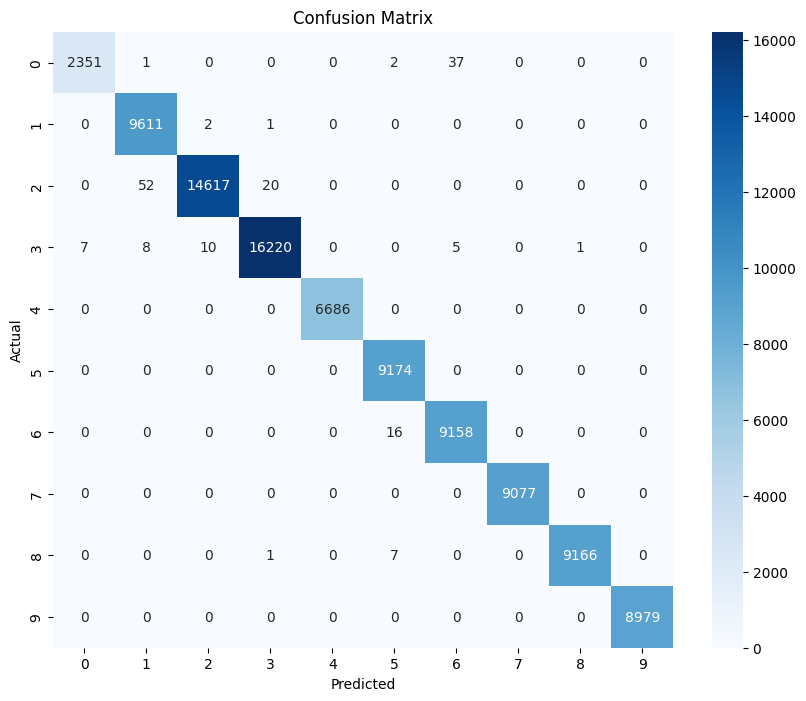

In [52]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10,8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [53]:
from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    digits=4
))

              precision    recall  f1-score   support

           0     0.9970    0.9833    0.9901      2391
           1     0.9937    0.9997    0.9967      9614
           2     0.9992    0.9951    0.9971     14689
           3     0.9986    0.9981    0.9984     16251
           4     1.0000    1.0000    1.0000      6686
           5     0.9973    1.0000    0.9986      9174
           6     0.9954    0.9983    0.9968      9174
           7     1.0000    1.0000    1.0000      9077
           8     0.9999    0.9991    0.9995      9174
           9     1.0000    1.0000    1.0000      8979

    accuracy                         0.9982     95209
   macro avg     0.9981    0.9974    0.9977     95209
weighted avg     0.9982    0.9982    0.9982     95209



In [54]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

print("Accuracy :", accuracy_score(y_true, y_pred))

print("Precision :", precision_score(
    y_true,
    y_pred,
    average="weighted"
))

print("Recall :", recall_score(
    y_true,
    y_pred,
    average="weighted"
))

print("F1 Score :", f1_score(
    y_true,
    y_pred,
    average="weighted"
))

Accuracy : 0.9982144545158546
Precision : 0.998218574925584
Recall : 0.9982144545158546
F1 Score : 0.9982133618822631


In [56]:
print(type(model))

<class 'keras.src.models.functional.Functional'>


In [57]:
print(model.history)

In [58]:
history = model.history

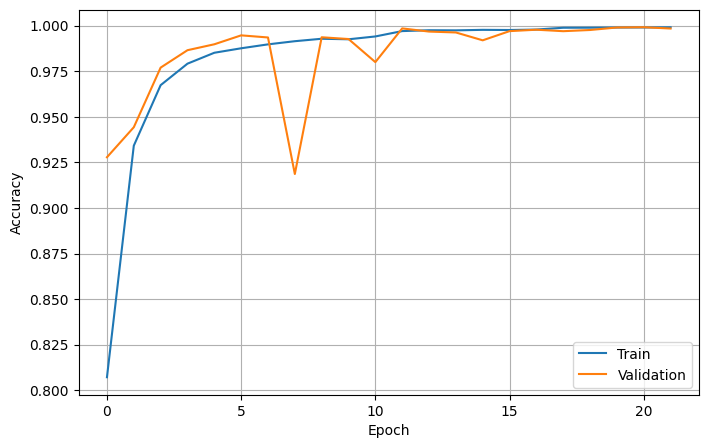

In [59]:
plt.figure(figsize=(8,5))

plt.plot(history.history["accuracy"], label="Train")

plt.plot(history.history["val_accuracy"], label="Validation")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.grid(True)

plt.show()

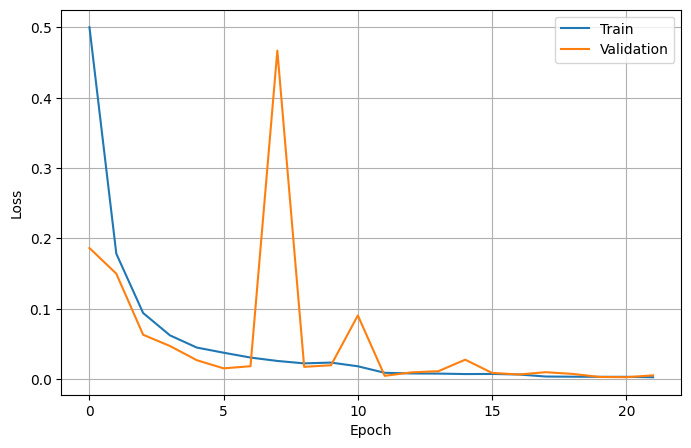

In [60]:
plt.figure(figsize=(8,5))

plt.plot(history.history["loss"], label="Train")

plt.plot(history.history["val_loss"], label="Validation")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.legend()

plt.grid(True)

plt.show()

In [61]:
import numpy as np
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

class_accuracy = cm.diagonal() / cm.sum(axis=1)

for i, acc in enumerate(class_accuracy):
    print(f"Class {i}: {acc*100:.2f}%")

Class 0: 98.33%
Class 1: 99.97%
Class 2: 99.51%
Class 3: 99.81%
Class 4: 100.00%
Class 5: 100.00%
Class 6: 99.83%
Class 7: 100.00%
Class 8: 99.91%
Class 9: 100.00%


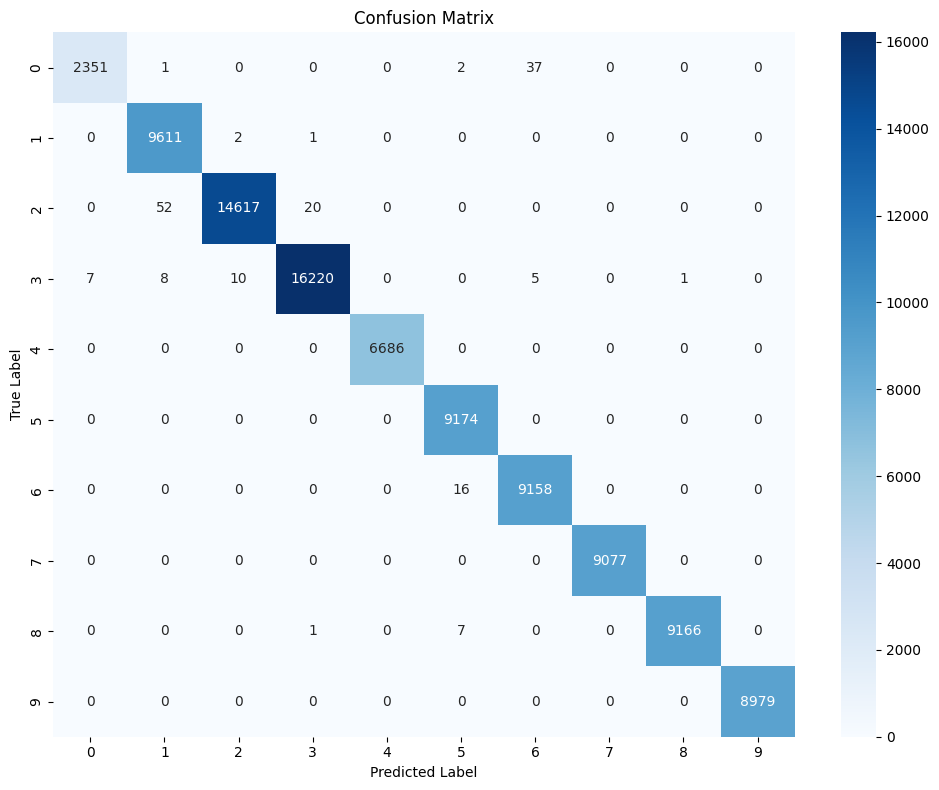

In [62]:
plt.figure(figsize=(10,8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")

plt.tight_layout()

plt.savefig("confusion_matrix.png", dpi=300)

plt.show()

In [63]:
plt.savefig("accuracy_curve.png", dpi=300)

<Figure size 640x480 with 0 Axes>

In [64]:
plt.savefig("loss_curve.png", dpi=300)

<Figure size 640x480 with 0 Axes>

In [65]:
import time

start = time.time()

_ = model.predict(X_test[:1000], verbose=0)

end = time.time()

print("Inference time:", end-start)

Inference time: 0.6595911979675293


In [66]:
import os

size = os.path.getsize("models/MHSF_CA_final.keras")/(1024*1024)

print(size,"MB")

FileNotFoundError: [WinError 2] The system cannot find the file specified: 'models/MHSF_CA_final.keras'

In [67]:
from tensorflow.keras import Model, layers

def build_mhsf_ca_net(
    input_shape=(1024, 3),
    num_classes=10,
    use_agff=True,
    use_residual=True,
    use_attention=True
):

    inputs = layers.Input(shape=input_shape)

    # Initial Conv
    x = InitialConv(inputs)

    # Multi-scale feature extraction
    multiscale = MultiScaleFeatureExtractionBlock(filters=64)
    f3, f5, f9 = multiscale(x)

    # ---------------------------------------------------
    # Adaptive Gated Feature Fusion
    # ---------------------------------------------------
    if use_agff:

        fusion = AdaptiveGatedFeatureFusion()
        x = fusion(f3, f5, f9)

    else:
        # Simple concatenation instead of AGFF
        x = layers.Concatenate(axis=-1)([f3, f5, f9])

        x = layers.Conv1D(
            64,
            kernel_size=1,
            padding="same",
            activation="relu"
        )(x)

    # ---------------------------------------------------
    # Residual Temporal Block
    # ---------------------------------------------------
    if use_residual:

        x = ResidualTemporalBlock(filters=64)(x)

    # ---------------------------------------------------
    # Cross-Channel Attention
    # ---------------------------------------------------
    if use_attention:

        x = CrossChannelAttention(channels=64)(x)

    # ---------------------------------------------------
    # Classifier
    # ---------------------------------------------------
    x = layers.GlobalAveragePooling1D()(x)

    x = layers.Dense(128, activation="relu")(x)

    x = layers.Dropout(0.5)(x)

    outputs = layers.Dense(num_classes, activation="softmax")(x)

    return Model(inputs, outputs)

In [68]:
full_model = build_mhsf_ca_net()

full_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [69]:
model_no_agff = build_mhsf_ca_net(
    use_agff=False
)

In [70]:
model_no_agff.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [71]:
history_no_agff = model_no_agff.fit(
    train_dataset,
    validation_data=test_dataset,
    epochs=10,
    callbacks=callbacks
)

Epoch 1/10
5951/5951 ━━━━━━━━━━━━━━━━━━━━ 1108s 185ms/step - accuracy: 0.7956 - loss: 0.5281 - val_accuracy: 0.8480 - val_loss: 0.4055 - learning_rate: 0.0010
Epoch 2/10
5951/5951 ━━━━━━━━━━━━━━━━━━━━ 1064s 179ms/step - accuracy: 0.9474 - loss: 0.1480 - val_accuracy: 0.9721 - val_loss: 0.0744 - learning_rate: 0.0010
Epoch 3/10
5951/5951 ━━━━━━━━━━━━━━━━━━━━ 1056s 177ms/step - accuracy: 0.9772 - loss: 0.0671 - val_accuracy: 0.9877 - val_loss: 0.0393 - learning_rate: 0.0010
Epoch 4/10
5951/5951 ━━━━━━━━━━━━━━━━━━━━ 1047s 176ms/step - accuracy: 0.9842 - loss: 0.0471 - val_accuracy: 0.9900 - val_loss: 0.0302 - learning_rate: 0.0010
Epoch 5/10
5951/5951 ━━━━━━━━━━━━━━━━━━━━ 0s 173ms/step - accuracy: 0.9881 - loss: 0.0352
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
5951/5951 ━━━━━━━━━━━━━━━━━━━━ 1087s 183ms/step - accuracy: 0.9881 - loss: 0.0355 - val_accuracy: 0.9887 - val_loss: 0.0327 - learning_rate: 0.0010
Epoch 6/10
5951/5951 ━━━━━━━━━━━━━━━━━━━━ 1095s 18

In [72]:
loss_no_agff, acc_no_agff = model_no_agff.evaluate(test_dataset)

print(f"Accuracy without AGFF : {acc_no_agff:.4f}")

1488/1488 ━━━━━━━━━━━━━━━━━━━━ 61s 41ms/step - accuracy: 0.8480 - loss: 0.4055
Accuracy without AGFF : 0.8480


In [73]:
model_no_agff.save("models/no_agff.keras")

In [74]:
y_pred_prob = model_no_agff.predict(X_test, verbose=1)
y_pred = np.argmax(y_pred_prob, axis=1)

2976/2976 ━━━━━━━━━━━━━━━━━━━━ 59s 20ms/step


In [75]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, digits=4))

              precision    recall  f1-score   support

           0     0.4765    0.5136    0.4944      2391
           1     0.7129    0.9231    0.8045      9614
           2     0.8193    0.7784    0.7984     14689
           3     0.8152    0.8825    0.8475     16251
           4     0.9991    0.9888    0.9939      6686
           5     0.9760    0.6373    0.7711      9174
           6     0.7051    0.8631    0.7761      9174
           7     0.9922    0.9975    0.9948      9077
           8     0.9882    0.7042    0.8224      9174
           9     0.9822    0.9993    0.9907      8979

    accuracy                         0.8480     95209
   macro avg     0.8467    0.8288    0.8294     95209
weighted avg     0.8641    0.8480    0.8479     95209



In [79]:
model_no_residual = build_mhsf_ca_net(
    use_residual=False
)

In [80]:
model_no_residual.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [81]:
history_no_residual = model_no_residual.fit(
    train_dataset,
    validation_data=test_dataset,
    epochs=5,
    callbacks=callbacks
)

Epoch 1/5
5951/5951 ━━━━━━━━━━━━━━━━━━━━ 964s 161ms/step - accuracy: 0.7278 - loss: 0.6968 - val_accuracy: 0.8277 - val_loss: 0.4356 - learning_rate: 0.0010
Epoch 2/5
5951/5951 ━━━━━━━━━━━━━━━━━━━━ 1541s 255ms/step - accuracy: 0.8268 - loss: 0.4463 - val_accuracy: 0.8563 - val_loss: 0.3583 - learning_rate: 0.0010
Epoch 3/5
5951/5951 ━━━━━━━━━━━━━━━━━━━━ 1517s 255ms/step - accuracy: 0.8619 - loss: 0.3573 - val_accuracy: 0.8926 - val_loss: 0.2678 - learning_rate: 0.0010
Epoch 4/5
5951/5951 ━━━━━━━━━━━━━━━━━━━━ 1255s 211ms/step - accuracy: 0.8829 - loss: 0.3066 - val_accuracy: 0.9089 - val_loss: 0.2296 - learning_rate: 0.0010
Epoch 5/5
5764/5951 ━━━━━━━━━━━━━━━━━━━━ 45s 241ms/step - accuracy: 0.8943 - loss: 0.2765

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



In [82]:
loss_no_residual, acc_no_residual = model_no_residual.evaluate(test_dataset)

print(f"Accuracy without Residual : {acc_no_residual:.4f}")

1488/1488 ━━━━━━━━━━━━━━━━━━━━ 88s 59ms/step - accuracy: 0.8277 - loss: 0.4356
Accuracy without Residual : 0.8277


In [83]:
model_no_residual.save("models/no_residual.keras")

In [84]:
y_pred_prob = model_no_residual.predict(X_test, verbose=1)
y_pred = np.argmax(y_pred_prob, axis=1)

2976/2976 ━━━━━━━━━━━━━━━━━━━━ 102s 33ms/step


In [85]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, digits=4))

              precision    recall  f1-score   support

           0     0.8637    0.3287    0.4762      2391
           1     0.8901    0.6935    0.7796      9614
           2     0.6299    0.9129    0.7455     14689
           3     0.9189    0.6216    0.7416     16251
           4     0.9902    0.9686    0.9793      6686
           5     0.7513    0.9275    0.8302      9174
           6     0.9067    0.7021    0.7914      9174
           7     0.9985    0.9716    0.9849      9077
           8     0.7496    0.9470    0.8368      9174
           9     0.9749    0.9923    0.9836      8979

    accuracy                         0.8277     95209
   macro avg     0.8674    0.8066    0.8149     95209
weighted avg     0.8543    0.8277    0.8246     95209



In [86]:
model_no_attention = build_mhsf_ca_net(
    use_attention=False
)

In [87]:
model_no_attention.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [88]:
history_no_attention = model_no_attention.fit(
    train_dataset,
    validation_data=test_dataset,
    epochs=5,
    callbacks=callbacks
)

Epoch 1/5
2999/5951 ━━━━━━━━━━━━━━━━━━━━ 16:33 337ms/step - accuracy: 0.6737 - loss: 0.8580

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



2576/5951 ━━━━━━━━━━━━━━━━━━━━ 13:14 235ms/step - accuracy: 0.9242 - loss: 0.2065

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



 991/5951 ━━━━━━━━━━━━━━━━━━━━ 27:51 337ms/step - accuracy: 0.9694 - loss: 0.0900

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



5951/5951 ━━━━━━━━━━━━━━━━━━━━ 2115s 355ms/step - accuracy: 0.9742 - loss: 0.0755 - val_accuracy: 0.9780 - val_loss: 0.0608 - learning_rate: 0.0010
Epoch 4/5
 736/5951 ━━━━━━━━━━━━━━━━━━━━ 29:05 335ms/step - accuracy: 0.9825 - loss: 0.0531

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



5812/5951 ━━━━━━━━━━━━━━━━━━━━ 39s 288ms/step - accuracy: 0.9822 - loss: 0.0531

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



5951/5951 ━━━━━━━━━━━━━━━━━━━━ 0s 335ms/step - accuracy: 0.9862 - loss: 0.0415
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
5951/5951 ━━━━━━━━━━━━━━━━━━━━ 2137s 359ms/step - accuracy: 0.9872 - loss: 0.0386 - val_accuracy: 0.9747 - val_loss: 0.0760 - learning_rate: 0.0010


In [89]:
loss_no_attention, acc_no_attention = model_no_attention.evaluate(test_dataset)

print(f"Accuracy without Attention : {acc_no_attention:.4f}")

1488/1488 ━━━━━━━━━━━━━━━━━━━━ 115s 77ms/step - accuracy: 0.8220 - loss: 0.4940
Accuracy without Attention : 0.8220


In [90]:
model_no_attention.save("models/no_attention.keras")

In [91]:
y_pred_prob = model_no_attention.predict(X_test, verbose=1)
y_pred = np.argmax(y_pred_prob, axis=1)

2976/2976 ━━━━━━━━━━━━━━━━━━━━ 132s 43ms/step


In [92]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, digits=4))

              precision    recall  f1-score   support

           0     0.2762    0.8662    0.4188      2391
           1     0.9309    0.8422    0.8843      9614
           2     0.9395    0.3498    0.5098     14689
           3     0.7425    0.9172    0.8207     16251
           4     0.9982    0.9939    0.9960      6686
           5     0.9446    0.7913    0.8611      9174
           6     0.9432    0.8152    0.8746      9174
           7     0.9999    0.9466    0.9725      9077
           8     0.6683    0.9943    0.7994      9174
           9     0.9996    0.9970    0.9983      8979

    accuracy                         0.8220     95209
   macro avg     0.8443    0.8514    0.8136     95209
weighted avg     0.8786    0.8220    0.8196     95209



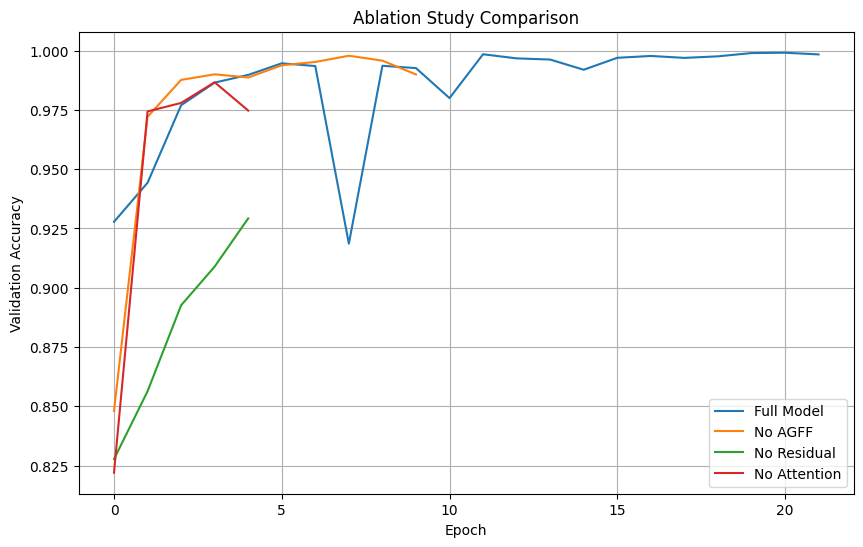

In [93]:
plt.figure(figsize=(10,6))

plt.plot(history.history["val_accuracy"], label="Full Model")
plt.plot(history_no_agff.history["val_accuracy"], label="No AGFF")
plt.plot(history_no_residual.history["val_accuracy"], label="No Residual")
plt.plot(history_no_attention.history["val_accuracy"], label="No Attention")

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Ablation Study Comparison")

plt.legend()
plt.grid(True)

plt.show()

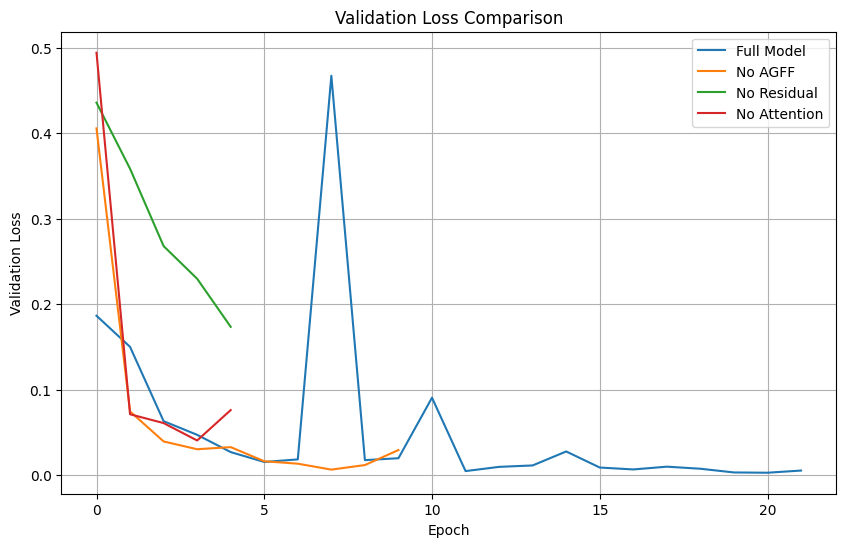

In [94]:
plt.figure(figsize=(10,6))

plt.plot(history.history["val_loss"], label="Full Model")
plt.plot(history_no_agff.history["val_loss"], label="No AGFF")
plt.plot(history_no_residual.history["val_loss"], label="No Residual")
plt.plot(history_no_attention.history["val_loss"], label="No Attention")

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Validation Loss Comparison")

plt.legend()
plt.grid(True)

plt.show()

In [95]:
class_names = [
    "Normal",
    "Horizontal Misalignment",
    "Vertical Misalignment",
    "Imbalance",
    "Underhang Ball",
    "Underhang Cage",
    "Underhang Outer",
    "Overhang Ball",
    "Overhang Cage",
    "Overhang Outer"
]

y_prob = model.predict(X_test)

for i in range(5):
    pred = np.argmax(y_prob[i])
    confidence = np.max(y_prob[i])

    print(f"Sample {i+1}")
    print(f"True Label      : {class_names[y_test[i]]}")
    print(f"Predicted Label : {class_names[pred]}")
    print(f"Confidence      : {confidence*100:.2f}%")
    print("-"*50)

2976/2976 ━━━━━━━━━━━━━━━━━━━━ 155s 52ms/step
Sample 1
True Label      : Overhang Cage
Predicted Label : Overhang Cage
Confidence      : 100.00%
--------------------------------------------------
Sample 2
True Label      : Horizontal Misalignment
Predicted Label : Horizontal Misalignment
Confidence      : 100.00%
--------------------------------------------------
Sample 3
True Label      : Overhang Ball
Predicted Label : Overhang Ball
Confidence      : 100.00%
--------------------------------------------------
Sample 4
True Label      : Horizontal Misalignment
Predicted Label : Horizontal Misalignment
Confidence      : 100.00%
--------------------------------------------------
Sample 5
True Label      : Vertical Misalignment
Predicted Label : Vertical Misalignment
Confidence      : 100.00%
--------------------------------------------------


In [96]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Predict
y_pred_prob = model_no_agff.predict(test_dataset, verbose=1)
y_pred = np.argmax(y_pred_prob, axis=1)

# Get true labels from the test dataset
y_true = np.concatenate([y.numpy() for _, y in test_dataset], axis=0)

# Metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average='weighted')
recall = recall_score(y_true, y_pred, average='weighted')
f1 = f1_score(y_true, y_pred, average='weighted')

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

1488/1488 ━━━━━━━━━━━━━━━━━━━━ 63s 41ms/step
Accuracy : 0.8480
Precision: 0.8641
Recall   : 0.8480
F1 Score : 0.8479


In [97]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Predict
y_pred_prob = model_no_residual.predict(test_dataset, verbose=1)
y_pred = np.argmax(y_pred_prob, axis=1)

# Get true labels from the test dataset
y_true = np.concatenate([y.numpy() for _, y in test_dataset], axis=0)

# Metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average='weighted')
recall = recall_score(y_true, y_pred, average='weighted')
f1 = f1_score(y_true, y_pred, average='weighted')

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

1488/1488 ━━━━━━━━━━━━━━━━━━━━ 41s 27ms/step
Accuracy : 0.8277
Precision: 0.8543
Recall   : 0.8277
F1 Score : 0.8246


In [98]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Predict
y_pred_prob = model_no_attention.predict(test_dataset, verbose=1)
y_pred = np.argmax(y_pred_prob, axis=1)

# Get true labels from the test dataset
y_true = np.concatenate([y.numpy() for _, y in test_dataset], axis=0)

# Metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred, average='weighted')
recall = recall_score(y_true, y_pred, average='weighted')
f1 = f1_score(y_true, y_pred, average='weighted')

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

1488/1488 ━━━━━━━━━━━━━━━━━━━━ 52s 35ms/step
Accuracy : 0.8220
Precision: 0.8786
Recall   : 0.8220
F1 Score : 0.8196


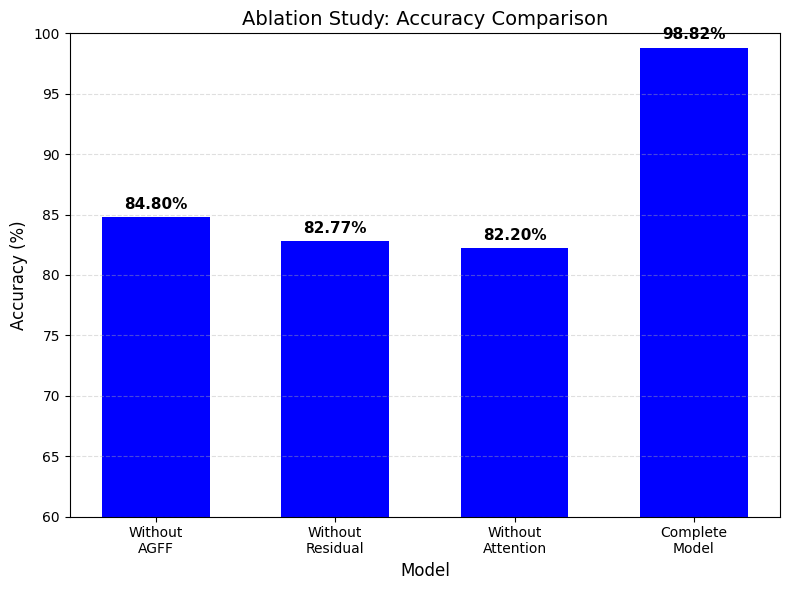

In [106]:
import matplotlib.pyplot as plt

# Model names
models = [
    "Without\nAGFF",
    "Without\nResidual",
    "Without\nAttention",
    "Complete\nModel"
]

# Replace these with your actual accuracies
accuracy = [
    84.80,   # Without AGFF
    82.77,   # Without Residual
    82.20,   # Without Attention
    98.82    # Proposed
]

plt.figure(figsize=(8,6))

bars = plt.bar(
    models,
    accuracy,
    color='blue',      # Manual blue color
    width=0.6
)

plt.ylabel("Accuracy (%)", fontsize=12)
plt.xlabel("Model", fontsize=12)
plt.title("Ablation Study: Accuracy Comparison", fontsize=14)

plt.ylim(60, 100)
plt.grid(axis='y', linestyle='--', alpha=0.4)

# Display values above bars
for bar, value in zip(bars, accuracy):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.45,
        f"{value:.2f}%",
        ha='center',
        va='bottom',
        fontsize=11,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()